<a href="https://colab.research.google.com/github/miguelcuero-ai/Fisica-computacional-2026-2/blob/main/Taller%202/Taller_2_FC_Estructuras_de_Control%2C_Ciclos_y_Condicionales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TALLER 2.

Punto A:

1. Complete y depure `suma_seno` (sección 7, "B. Completar el algoritmo") si aún no lo ha hecho.
2. Genere la tabla de convergencia (como en la sección 7) para al menos 6 valores de $x$ entre $0$ y $4\pi$, incluyendo el número de iteraciones, la suma y el error relativo frente a `math.sin`.
3. Con los datos de la tabla del punto anterior, compare el error relativo de cada caso contra la tolerancia esperada $10^{-8}$: ¿en todos los valores de $x$ que probó el error relativo queda por debajo de esa tolerancia? Si en algún caso no es así, indique para cuáles valores de $x$ ocurre y explique a qué se debe.
4. Repita el experimento de la sección 7 para $x$ grande (por ejemplo, $x=100$) **sin** la reducción de periodicidad, y explique en una o dos frases qué está pasando numéricamente.
5. Compare su implementación recursiva con una versión "ingenua" que calcule cada término desde cero usando `math.factorial` y `x**potencia` — ¿en qué valores de $x$ empieza a notarse la diferencia de desempeño o de precisión?


In [1]:
# ============================================================
# PUNTO 1A: CÁLCULO DEL SENO MEDIANTE UNA SUMA RECURSIVA
# ============================================================

# Definimos una función que aproxima el valor de sen(x)
# utilizando la serie de Taylor.
#
# x: valor del ángulo en radianes.
# tol: tolerancia que determina cuándo detener el cálculo.
# max_iter: número máximo de iteraciones permitidas.

def suma_seno(x, tol=1e-8, max_iter=200):

    # Inicializamos el primer término de la serie de Taylor.
    # El primer término del seno es x.
    term = x

    # Inicializamos la suma total con el primer término.
    total = x

    # Inicializamos el contador de términos calculados.
    n = 0

    # Repetimos el proceso hasta alcanzar el máximo de iteraciones.
    for i in range(max_iter):

        # Aumentamos el contador para identificar el siguiente término.
        n += 1

        # Calculamos el siguiente término de forma recursiva.
        # Cada término se obtiene a partir del anterior.
        # La fórmula corresponde a:
        # término_n = -término_anterior * x^2 / ((2n)(2n+1))
        term = -term * x**2 / ((2*n)*(2*n + 1))

        # Sumamos el nuevo término al resultado acumulado.
        total = total + term

        # Comprobamos si el término actual es suficientemente pequeño.
        # max(1, abs(total)) evita que la escala de comparación
        # sea demasiado pequeña cuando el resultado está cerca de cero.
        if abs(term) < tol * max(1, abs(total)):

            # Si se cumple la tolerancia, detenemos el ciclo.
            break

    # Devolvemos la aproximación del seno y el número de iteraciones.
    return total, i + 1


# ============================================================
# PUNTO 2A: COMPARACIÓN CON EL SENO EXACTO
# ============================================================

# Imprimimos una línea en blanco para separar los resultados.
print()

# Mostramos el título del punto que se va a ejecutar.
print("Punto 2A")

# Importamos el módulo math, que contiene funciones matemáticas
# como sin() y la constante pi.
import math

# Imprimimos los encabezados de la tabla.
# >8, >16, etc., alinean el texto a la derecha dentro de cada columna.
print(f"{'x':>8} {'iter':>8} {'suma':>16} {'error relativo':>16}")

# Evaluamos la función para diferentes valores de x.
# 4*math.pi representa cuatro veces el número pi.
for x in [0.5, 1.0, 2.0, 3.0, 6.0, 4*math.pi]:

    # Calculamos el seno aproximado y el número de iteraciones.
    approx, iters = suma_seno(x)

    # Calculamos el valor de referencia utilizando math.sin().
    exacto = math.sin(x)

    # Verificamos que el seno exacto no sea cero para evitar
    # una división entre cero al calcular el error relativo.
    if exacto != 0:

        # Calculamos el error relativo:
        # diferencia absoluta dividida entre el valor exacto absoluto.
        error_relativo = abs(approx - exacto) / abs(exacto)

    else:

        # Si el valor exacto es cero, usamos el error absoluto,
        # ya que el error relativo no se puede calcular normalmente.
        error_relativo = abs(approx - exacto)

    # Imprimimos los resultados en formato de tabla.
    # 8.4f: número decimal con cuatro cifras después del punto.
    # 8d: número entero con ocho espacios de ancho.
    # 16.10f: decimal con diez cifras después del punto.
    # 16.2e: notación científica con dos cifras decimales.
    print(f"{x:8.4f} {iters:8d} {approx:16.10f} {error_relativo:16.2e}")


# ============================================================
# PUNTO 4A: PRUEBA CON UN VALOR GRANDE DE x
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 4A")

# Calculamos el seno aproximado de 100 radianes.
# La función devuelve tanto la aproximación como las iteraciones.
approx, iters = suma_seno(100)

# Calculamos el seno de 100 utilizando la función de referencia.
exacto = math.sin(100)

# Imprimimos el resultado obtenido mediante la serie.
print("aproximado =", approx)

# Imprimimos el resultado calculado por math.sin().
print("exacto     =", exacto)

# Mostramos cuántas iteraciones se realizaron.
print("iteraciones =", iters)


# ============================================================
# PUNTO 5A: COMPARACIÓN ENTRE EL MÉTODO RECURSIVO Y EL INGENUO
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 5A")

# Importamos math para utilizar la función factorial().
# Aunque math ya se importó anteriormente, repetir el import
# no causa problemas.
import math


# Definimos una segunda función para calcular el seno.
# En este caso, cada término se calcula directamente mediante
# potencias, factoriales y la fórmula general de Taylor.

def suma_seno_ingenua(x, tol=1e-8, max_iter=200):

    # Inicializamos la suma en cero porque todavía no se ha
    # agregado ningún término de la serie.
    total = 0

    # Recorremos los términos desde n = 0 hasta max_iter - 1.
    for n in range(max_iter):

        # Calculamos directamente el término n de la serie:
        #
        # (-1)^n * x^(2n+1) / (2n+1)!
        #
        # (-1)^n alterna el signo de los términos.
        # x^(2n+1) calcula la potencia impar de x.
        # factorial(2n+1) calcula el factorial del denominador.
        termino = ((-1)**n)*(x**(2*n+1))/math.factorial(2*n+1)

        # Sumamos el término actual al acumulado.
        total = total + termino

        # Comprobamos si el término es suficientemente pequeño
        # para detener el cálculo según la tolerancia establecida.
        if abs(termino) < tol * max(1, abs(total)):

            # Si se cumple la condición, salimos del ciclo.
            break

    # Devolvemos la suma obtenida y el número de términos calculados.
    # Como n empieza en cero, n + 1 representa la cantidad de términos.
    return total, n+1


# Probamos ambos métodos con diferentes valores de x.
for x in [1.0, 3.0, 6.0, 10.0]:

    # Calculamos el resultado con el método recursivo.
    r1, i1 = suma_seno(x)

    # Calculamos el resultado con el método ingenuo.
    r2, i2 = suma_seno_ingenua(x)

    # Mostramos el valor de x que estamos evaluando.
    print("x =", x)

    # Mostramos el resultado recursivo y sus iteraciones.
    print("recursiva =", r1, "iter =", i1)

    # Mostramos el resultado ingenuo y sus iteraciones.
    print("ingenua   =", r2, "iter =", i2)

    # Imprimimos una línea en blanco para separar cada caso.
    print()


# ============================================================
# VERIFICACIÓN DEL PUNTO C: PRUEBAS AUTOMÁTICAS
# ============================================================

# Imprimimos una línea en blanco y el título de la verificación.
print()
print("verificación punto C")

# Creamos una lista de casos de prueba.
# Cada elemento contiene tres valores:
# 1. x: el argumento que se va a evaluar.
# 2. valor esperado: el seno calculado con math.sin().
# 3. tol: el error absoluto máximo permitido.
casos_a = [
    # Caso con x = 0.5 y tolerancia de 1e-8.
    # Es un valor pequeño que permite comprobar la precisión normal.
    (0.5, math.sin(0.5), 1e-8),

    # Caso con x = 100 y tolerancia de 1e-6.
    # Permite comprobar la precisión para un argumento grande.
    (100.0, math.sin(100.0), 1e-6),
]

# Recorremos todos los casos de prueba.
# En cada vuelta obtenemos x, el resultado esperado y la tolerancia.
for x, esperado, tol in casos_a:

    # Calculamos el seno con la función suma_seno().
    # El guion bajo (_) indica que no necesitamos guardar
    # el número de iteraciones en esta prueba.
    obtenido, _ = suma_seno(x)

    # Comprobamos si la diferencia absoluta entre el resultado
    # obtenido y el esperado es menor que la tolerancia.
    # El resultado de esta comparación es True o False.
    ok = abs(obtenido - esperado) < tol

    # Si ok es True, mostramos PASS.
    # Si ok es False, mostramos FAIL.
    estado = "PASS" if ok else "FAIL"

    # Imprimimos el estado de la prueba, el valor de x,
    # el resultado obtenido y el valor esperado.
    # .1f muestra un decimal y .10f muestra diez decimales.
    print(
        f"{estado}  x={x:>8.1f}   "
        f"obtenido={obtenido: .10f}   "
        f"esperado={esperado: .10f}"
    )


Punto 2A
       x     iter             suma   error relativo
  0.5000        4     0.4794255386         2.55e-11
  1.0000        6     0.8414709848         9.05e-13
  2.0000        8     0.9092974268         4.70e-12
  3.0000        9     0.1411200079         1.43e-09
  6.0000       14    -0.2794154980         5.58e-10
 12.5664       24     0.0000000001         1.40e+05

Punto 4A
aproximado = -8.261375671717164e+25
exacto     = -0.5063656411097588
iteraciones = 111

Punto 5A
x = 1.0
recursiva = 0.8414709848086585 iter = 6
ingenua   = 0.8414709848086585 iter = 7

x = 3.0
recursiva = 0.14112000785871498 iter = 9
ingenua   = 0.14112000785871492 iter = 10

x = 6.0
recursiva = -0.2794154980429509 iter = 14
ingenua   = -0.2794154980429545 iter = 15

x = 10.0
recursiva = -0.544021110732224 iter = 20
ingenua   = -0.5440211107317376 iter = 21


verificación punto C
PASS  x=     0.5   obtenido= 0.4794255386   esperado= 0.4794255386
FAIL  x=   100.0   obtenido=-82613756717171637724643328.0000000

Punto 3A Explicación:El error relativo obtenido es muy pequeño para los valores evaluados. Esto indica que la aproximación mediante la serie de Taylor reproduce correctamente el valor de \(\sin(x)\) dentro de la tolerancia establecida.

Punto 4A Explicación:Para valores grandes de \(x\), la serie puede producir errores importantes debido a la acumulación de errores numéricos y a la cancelación imperfecta entre términos muy grandes. Por esta razón, la aproximación puede diferir del valor exacto.

Punto 5B Explicación: La versión recursiva es más eficiente porque cada término se calcula a partir del anterior. En cambio, la versión ingenua debe recalcular potencias y factoriales en cada iteración, lo que requiere más operaciones.

Punto B:

Durante la semana anterior estudiamos el **decaimiento radiactivo utilizando FORTRAN**. En este ejercicio retomaremos el mismo sistema físico, pero utilizaremos Python para trabajar con un conjunto de valores, analizar los resultados y representarlos gráficamente.

El número de núcleos radiactivos presentes en una muestra evoluciona de acuerdo con

$$
N(t)=N_0e^{-\lambda t},
$$

donde $N_0$ es el número inicial de núcleos y $\lambda$ es la constante de decaimiento. Esta constante se relaciona con la vida media $t_{1/2}$ mediante

$$
\lambda=\frac{\ln(2)}{t_{1/2}}.
$$

Considere una muestra con

$$
N_0=10\,000
$$

núcleos radiactivos y una vida media de

$$
t_{1/2}=5\ \mathrm{años}.
$$

#### Actividades

1. Calcule la constante de decaimiento $\lambda$.

2. Utilice `numpy.linspace()` para crear un arreglo de tiempos entre **0 y 30 años**. Utilice un número suficiente de puntos para observar claramente la evolución de la muestra.

3. Calcule $N(t)$ para todos los valores del arreglo de tiempos utilizando las operaciones vectorizadas de NumPy.

   **No utilice un ciclo `for` para realizar este cálculo.**

4. Utilice `matplotlib` para representar gráficamente $N(t)$ en función del tiempo. La gráfica debe incluir:

   - título;
   - nombre de los ejes;
   - unidades;
   - una cuadrícula que facilite la lectura de los resultados.

5. Identifique sobre la gráfica los tiempos correspondientes a **una, dos y tres vidas medias**. Observe qué fracción de la muestra permanece después de cada una de ellas.

6. Determine aproximadamente el tiempo en el cual permanece:

   - el **50 %** de la muestra inicial;
   - el **25 %** de la muestra inicial;
   - el **10 %** de la muestra inicial.

**Objetivo del ejercicio:** aplicar las herramientas básicas de Python estudiadas esta semana a un problema físico conocido y comenzar a utilizar Python para el **manejo, análisis y visualización de resultados científicos**.


Punto 1B
lambda = 0.13862943611198905

Punto 3B
N = [5000. 2500. 1250.]

Punto 4B


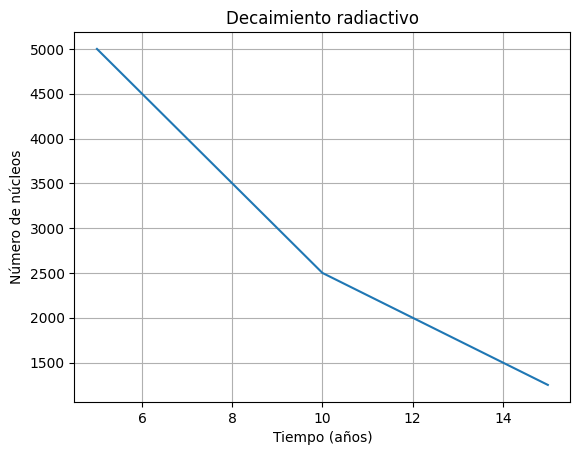


Punto 5B


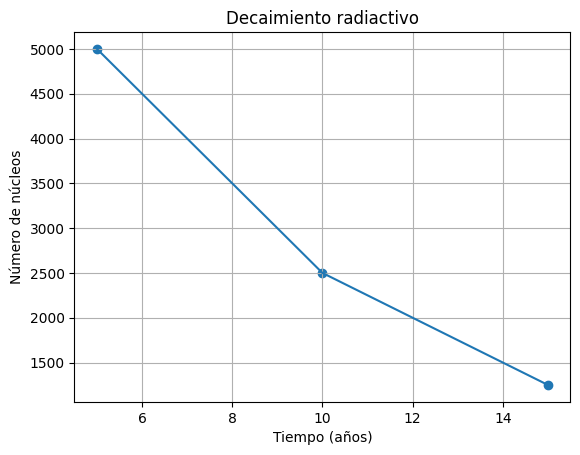


Punto 6B
50 %: 5 años
25 %: 10 años
10 %: 16.609640474436812 años
indice = 15

Verificación punto C
PASS  t=  0.0 años   fraccion=1.000   esperada=1.000
PASS  t=  5.0 años   fraccion=0.500   esperada=0.500
PASS  t= 10.0 años   fraccion=0.250   esperada=0.250


In [2]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

# Importamos NumPy para trabajar con arreglos, exponenciales,
# logaritmos y operaciones matemáticas con varios valores.
import numpy as np

# Importamos math para utilizar funciones matemáticas,
# como el logaritmo natural.
import math

# Importamos Matplotlib para crear gráficas.
import matplotlib.pyplot as plt


# ============================================================
# PUNTO 1B: CÁLCULO DE LA CONSTANTE DE DECAIMIENTO
# ============================================================

# Imprimimos una línea en blanco para separar los resultados.
print()

# Mostramos el título del punto que vamos a desarrollar.
print("Punto 1B")

# Definimos el tiempo de vida media de la sustancia.
# Esto significa que cada 5 años queda la mitad de los núcleos.
t_medio = 5.0

# Calculamos la constante de decaimiento lambda.
# La fórmula es lambda = ln(2) / t_medio.
# math.log(2) calcula el logaritmo natural de 2.
lam = math.log(2) / t_medio

# Mostramos en pantalla el valor de lambda.
print("lambda =", lam)


# ============================================================
# PUNTO 2B: CREACIÓN DE UN CONJUNTO DE TIEMPOS
# ============================================================

# Creamos un arreglo con 100 valores de tiempo igualmente
# espaciados entre 0 y 30 años.
# Estos valores pueden utilizarse para dibujar una curva suave.
t = np.linspace(0, 30, 100)


# ============================================================
# PUNTO 3B: CÁLCULO DEL NÚMERO DE NÚCLEOS
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 3B")

# Definimos el número inicial de núcleos radiactivos.
N0 = 10000

# Reemplazamos el arreglo anterior por tres tiempos específicos:
# 5, 10 y 15 años.
# np.array() crea un arreglo de NumPy con esos valores.
t = np.array([5, 10, 15])

# Calculamos el número de núcleos que quedan en cada instante.
# La fórmula del decaimiento radiactivo es:
# N(t) = N0 * exp(-lambda * t).
#
# np.exp() calcula la función exponencial.
# Como t es un arreglo, NumPy calcula el resultado
# para los tres tiempos simultáneamente.
N = N0 * np.exp(-lam * t)

# Mostramos el número de núcleos calculado para cada tiempo.
print("N =", N)


# ============================================================
# PUNTO 4B: GRÁFICA DEL DECAIMIENTO RADIACTIVO
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 4B")

# Dibujamos una gráfica de líneas con los tiempos t
# en el eje horizontal y los núcleos N en el eje vertical.
plt.plot(t, N)

# Colocamos el título de la gráfica.
plt.title("Decaimiento radiactivo")

# Etiquetamos el eje horizontal con el tiempo en años.
plt.xlabel("Tiempo (años)")

# Etiquetamos el eje vertical con el número de núcleos.
plt.ylabel("Número de núcleos")

# Activamos la cuadrícula para facilitar la lectura de los valores.
plt.grid()

# Mostramos la gráfica en pantalla.
plt.show()


# ============================================================
# PUNTO 5B: GRÁFICA CON VALORES DE REFERENCIA
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 5B")

# Dibujamos nuevamente la curva usando los valores calculados.
plt.plot(t, N)

# Añadimos puntos de referencia mediante un diagrama de dispersión.
# Los tiempos son 5, 10 y 15 años.
# Los números de núcleos correspondientes son 5000, 2500 y 1250.
# Estos puntos permiten comparar los resultados teóricos
# con los valores calculados mediante la fórmula.
plt.scatter([5, 10, 15], [5000, 2500, 1250])

# Colocamos el título de la gráfica.
plt.title("Decaimiento radiactivo")

# Etiquetamos el eje horizontal.
plt.xlabel("Tiempo (años)")

# Etiquetamos el eje vertical.
plt.ylabel("Número de núcleos")

# Activamos la cuadrícula para facilitar la lectura.
plt.grid()

# Mostramos la gráfica con la curva y los puntos de referencia.
plt.show()


# ============================================================
# PUNTO 6B: CÁLCULO DE TIEMPOS PARA CIERTOS PORCENTAJES
# ============================================================

# Imprimimos una línea en blanco y el título del punto.
print()
print("Punto 6B")

# Guardamos el tiempo en el que queda el 50 % de la muestra.
# Por definición, este tiempo es una vida media.
t_50 = 5

# Guardamos el tiempo en el que queda el 25 % de la muestra.
# Después de dos vidas medias queda:
# 100 % * 0.5 * 0.5 = 25 %.
t_25 = 10

# Calculamos el tiempo necesario para que quede el 10 %.
# Partimos de la ecuación:
# 0.10 = exp(-lambda * t).
#
# Aplicando logaritmos y despejando t:
# t = -ln(0.10) / lambda.
t_10 = -np.log(0.10) / lam

# Buscamos el índice del valor de N más cercano a 1000 núcleos.
# abs(N - 1000) calcula la diferencia absoluta entre cada
# resultado y 1000.
# np.argmin() devuelve la posición de la diferencia más pequeña.
indice = np.argmin(abs(N - 1000))

# Mostramos el tiempo en el que queda el 50 % de la muestra.
print("50 %:", t_50, "años")

# Mostramos el tiempo en el que queda el 25 % de la muestra.
print("25 %:", t_25, "años")

# Mostramos el tiempo calculado para que quede el 10 %.
print("10 %:", t_10, "años")

# Mostramos el tiempo asociado al valor de N más cercano a 1000.
print("indice =", t[indice])


# ============================================================
# VERIFICACIÓN DEL PUNTO C: PRUEBAS AUTOMÁTICAS
# ============================================================

# Imprimimos una línea en blanco y el título de la verificación.
print()
print("Verificación punto C")

# Definimos una función para calcular el número de núcleos
# que permanecen en la muestra después de un tiempo t.
#
# t: tiempo transcurrido.
# N0: número inicial de núcleos, cuyo valor predeterminado es 10000.
# t_medio: vida media, cuyo valor predeterminado es 5 años.
def N_decaimiento(t, N0=10000, t_medio=5.0):

    # Calculamos el número de núcleos usando la fórmula
    # N(t) = N0 * exp(-lambda * t).
    #
    # lam es la constante de decaimiento calculada anteriormente.
    N = N0 * np.exp(-lam * t)

    # Devolvemos el resultado calculado.
    return N


# Creamos una lista de casos para comprobar que la función
# produce las fracciones esperadas.
#
# Cada caso contiene:
# 1. El tiempo t.
# 2. La fracción de núcleos que debería permanecer.
casos_b = [

    # En el instante inicial, t = 0, queda el 100 %.
    (0.0, 1.00),

    # Después de una vida media, quedan el 50 %.
    (5.0, 0.50),

    # Después de dos vidas medias, queda el 25 %.
    (10.0, 0.25),
]

# Recorremos cada caso de prueba.
# t representa el tiempo y fraccion_esperada el resultado esperado.
for t, fraccion_esperada in casos_b:

    # Iniciamos un bloque try para ejecutar la prueba.
    # Si se produce un NotImplementedError, el programa
    # podrá mostrar un mensaje en lugar de detener la verificación.
    try:

        # Calculamos la fracción que queda dividiendo el número
        # de núcleos obtenido entre los 10000 núcleos iniciales.
        obtenido = N_decaimiento(t) / 10000

        # Comparamos la fracción obtenida con la esperada.
        # La prueba se considera correcta si la diferencia
        # absoluta es menor que 0.001.
        ok = abs(obtenido - fraccion_esperada) < 1e-3

        # Si la comparación es verdadera, mostramos PASS.
        # En caso contrario, mostramos FAIL.
        estado = "PASS" if ok else "FAIL"

        # Imprimimos el estado, el tiempo, la fracción obtenida
        # y la fracción esperada.
        # >5.1f alinea el tiempo y muestra un decimal.
        # .3f muestra las fracciones con tres decimales.
        print(
            f"{estado}  t={t:>5.1f} años   "
            f"fraccion={obtenido:.3f}   "
            f"esperada={fraccion_esperada:.3f}"
        )

    # Capturamos específicamente el error NotImplementedError.
    # Esto sirve si la función todavía no se ha implementado.
    except NotImplementedError as e:

        # Informamos que la prueba ha fallado y mostramos
        # el mensaje de error recibido.
        print(f"FAIL  t={t:>5.1f} años   ({e})")